# NeonLens · Tarea 7: red neuronal artificial
## Pregunta
¿Puede una RNA distinguir degradaciones controladas de iluminación, contraste y nitidez?
**Objetivo:** definir, entrenar, evaluar y usar una red 5→24→12→5. Relación con SEMANA 12: NumPy, píxeles, Flask y filtros OpenCV.
**Datos:** generados proceduralmente con semilla 42, sin fotos personales ni descargas. Sus etiquetas indican la transformación aplicada; no son opiniones humanas de calidad. La evaluación no demuestra rendimiento en fotografías reales.

In [1]:
import os, sys
from pathlib import Path
root = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(root))
import numpy as np, matplotlib.pyplot as plt, json
from vision import dataset, LABELS, FEATURES
from train import train, predict
from sklearn.model_selection import GroupShuffleSplit
x,y,groups=dataset()
print('Forma:', x.shape, 'Escenas:',len(np.unique(groups)))
print('Clases:',dict(zip(LABELS,np.bincount(y).tolist())))
print('Valores finitos:',np.isfinite(x).all(), 'Rango:',x.min(axis=0),x.max(axis=0))

Forma: (2500, 5) Escenas: 500
Clases: {'Equilibrada': 500, 'Oscura': 500, 'Sobreexpuesta': 500, 'Bajo contraste': 500, 'Desenfocada': 500}
Valores finitos: True Rango: [0.07176681 0.01942071 0.10678628 0.         0.        ] [0.97769799 0.31444119 0.81624504 1.         1.        ]


## Exploración de datos y características
Las cinco clases están balanceadas. La nitidez usa la varianza del Laplaciano comprimida con log1p; sombras y luces miden proporciones. Se calculan las mismas características en la API.

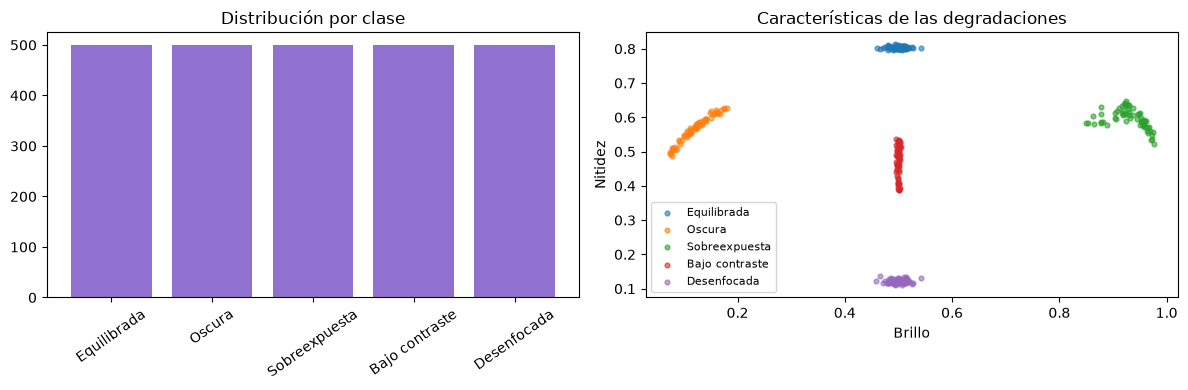

In [2]:
fig,axs=plt.subplots(1,2,figsize=(12,4))
axs[0].bar(LABELS,np.bincount(y),color='#9171cf');axs[0].tick_params(axis='x',rotation=35);axs[0].set_title('Distribución por clase')
for i,label in enumerate(LABELS):
    axs[1].scatter(x[y==i,0][::8],x[y==i,2][::8],s=12,label=label,alpha=.6)
axs[1].set(xlabel='Brillo',ylabel='Nitidez',title='Características de las degradaciones');axs[1].legend(fontsize=8)
plt.tight_layout();plt.show()

## Separación y prevención de fugas
GroupShuffleSplit separa escenas: todas las variantes de una escena permanecen en el mismo conjunto. StandardScaler se ajusta únicamente en entrenamiento. La validación interna de parada temprana no separa escenas; el holdout final sí lo hace.

In [3]:
a,b=next(GroupShuffleSplit(n_splits=1,test_size=.2,random_state=42).split(x,y,groups))
assert not set(groups[a]) & set(groups[b])
print('Entrenamiento:',len(a),'Prueba:',len(b),'Escenas compartidas: 0')

Entrenamiento: 2000 Prueba: 500 Escenas compartidas: 0


## Estructura y entrenamiento
MLPClassifier: 5 entradas → Dense(24, ReLU) → Dense(12, ReLU) → 5 salidas softmax. Adam optimiza entropía cruzada; máximo 250 iteraciones, parada temprana y 15% de validación interna. Se exportan los pesos y el escalador para inferencia NumPy sin pickle.

In [4]:
metrics=train()
print('Accuracy:',metrics['accuracy'],'F1 macro:',metrics['f1_macro'])
print('Baseline mayoritario:',metrics['baseline_accuracy'])
print(json.dumps(metrics['classification_report'],indent=2,ensure_ascii=False))

Accuracy: 1.0 F1 macro: 1.0
Baseline mayoritario: 0.2
{
  "Equilibrada": {
    "precision": 1.0,
    "recall": 1.0,
    "f1-score": 1.0,
    "support": 100.0
  },
  "Oscura": {
    "precision": 1.0,
    "recall": 1.0,
    "f1-score": 1.0,
    "support": 100.0
  },
  "Sobreexpuesta": {
    "precision": 1.0,
    "recall": 1.0,
    "f1-score": 1.0,
    "support": 100.0
  },
  "Bajo contraste": {
    "precision": 1.0,
    "recall": 1.0,
    "f1-score": 1.0,
    "support": 100.0
  },
  "Desenfocada": {
    "precision": 1.0,
    "recall": 1.0,
    "f1-score": 1.0,
    "support": 100.0
  },
  "accuracy": 1.0,
  "macro avg": {
    "precision": 1.0,
    "recall": 1.0,
    "f1-score": 1.0,
    "support": 500.0
  },
  "weighted avg": {
    "precision": 1.0,
    "recall": 1.0,
    "f1-score": 1.0,
    "support": 500.0
  }
}


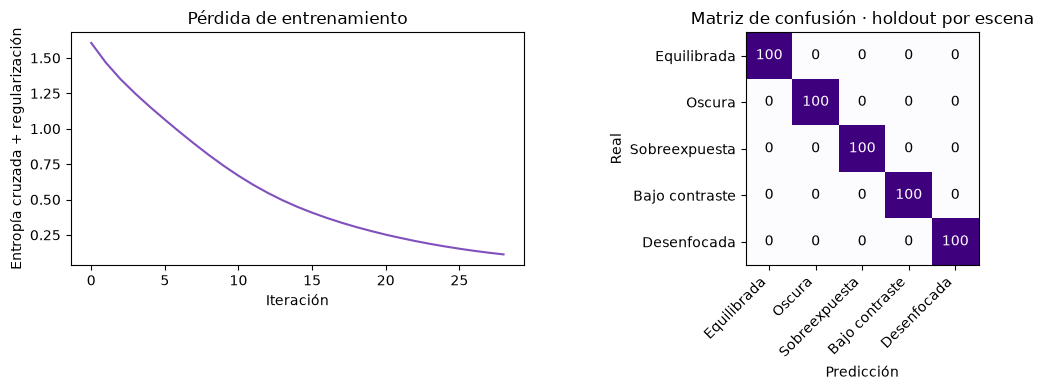

In [5]:
fig,axs=plt.subplots(1,2,figsize=(11,4))
axs[0].plot(metrics['loss'],color='#8050bc');axs[0].set(title='Pérdida de entrenamiento',xlabel='Iteración',ylabel='Entropía cruzada + regularización')
cm=np.array(metrics['confusion_matrix']);axs[1].imshow(cm,cmap='Purples')
axs[1].set_xticks(range(5),LABELS,rotation=45,ha='right');axs[1].set_yticks(range(5),LABELS)
axs[1].set(title='Matriz de confusión · holdout por escena',xlabel='Predicción',ylabel='Real')
for i in range(5):
    for j in range(5): axs[1].text(j,i,str(cm[i,j]),ha='center',va='center',color='white' if cm[i,j]>50 else 'black')
plt.tight_layout();plt.show()

## Prueba adicional reproducible
Se generan escenas nuevas con otra semilla. Esta prueba sigue siendo sintética y no reemplaza un conjunto de fotos reales etiquetadas.

In [6]:
xx,yy,_=dataset(seed=2026,groups=30)
pred=np.array([predict(v).argmax() for v in xx])
print('Exactitud escenas nuevas:',np.mean(pred==yy))
print('Ejemplo de probabilidades:',dict(zip(LABELS,predict(xx[0]).round(4).tolist())))
assert np.isfinite(predict(np.zeros(5))).all()

Exactitud escenas nuevas: 1.0
Ejemplo de probabilidades: {'Equilibrada': 0.7632, 'Oscura': 0.1063, 'Sobreexpuesta': 0.0472, 'Bajo contraste': 0.037, 'Desenfocada': 0.0463}


## Análisis crítico y siguientes pasos
Las degradaciones sintéticas son fáciles de separar: una métrica perfecta no implica un modelo perfecto. Fotos reales incluyen ruido, bokeh intencional, sombras artísticas y múltiples defectos simultáneos; el modelo devuelve una sola clase dominante. La probabilidad softmax no está calibrada como confianza real.

Para ampliar: recopilar fotografías con consentimiento, anotación de varios evaluadores, separación por fotógrafo/dispositivo, clases simultáneas, calibración y comparación con métodos por umbral. No se realizó esa evaluación en este proyecto.

## Despliegue y privacidad
Flask recibe archivos en memoria, limita tamaño y píxeles, normaliza RGB, extrae características e infiere. OpenCV aplica filtros deterministas. No hay login ni tokens de usuario; ver `docs/AUTHENTICATION.md`. Los PNG exportados no conservan EXIF. Las pruebas automatizadas están en `tests/test_app.py`.

## Conclusión
Se definió, entrenó, exportó e integró una RNA con evidencia reproducible. Su utilidad educativa es explorar la relación entre píxeles, degradaciones y predicción; su utilidad práctica es ofrecer comparación y filtros de imágenes sin historial persistente.